# Standalone HydroMT-SFINCS Direct Pipeline
Kernel: **HydroMT-SFINCS** (`env-sfincs`)

This notebook runs the automated **HydroMT-SFINCS flood hazard modeling workflow** for Sumatra Barat:
1. **40m 2D Computational Grid** coupled with **10m FABDEM subgrid** tables (High speed + 10m channel fidelity).
2. **Direct Rainfall-on-Grid** (SCS-derived design storms RP2 to RP100) applied across the active DAS cluster.
3. **Modular BWS Placeholders** for future river surveys, flood levees/embankments, and AWLR observation points.
4. **Automated SFINCS solver execution** (local Windows native binary `sfincs.exe` or Docker).
5. **High-resolution (10m) flood depth downscaling**, **Fuzzy Large Flood Hazard Index (0 to 1)**, and **Perka BNPB No. 2/2012 hazard classification**.

---
## 📌 USER CONFIGURATION CONTROL PANEL (Modify Here Only)

> **GUIDELINE FOR USERS & TEAM MEMBERS:**  
> You **ONLY need to adjust the variables in the cell below**. All subsequent pipeline steps (Grid Building, Rainfall Forcing, SFINCS Simulation, 10m Downscaling, BNPB Classification, and Visualization) will automatically adapt.
>
> ### Examples of Common Scenarios:
>
> * **Scenario A: Process a Single Cluster with a Single Return Period (e.g. DAS 102, RP100)**
>   ```python
>   SELECTED_CLUSTERS = ["DAS_108_D"]
>   SELECTED_RPS = ["rp100"]
>   ```
> * **Scenario B: Process a Single Cluster for ALL Return Periods (e.g. DAS 101, RP2 to RP100)**
>   ```python
>   SELECTED_CLUSTERS = ["DAS_101"]
>   SELECTED_RPS = ["rp2", "rp5", "rp10", "rp25", "rp50", "rp100"]
>   ```
> * **Scenario C: Batch Process Multiple Clusters for a 100-Year Flood (RP100)**
>   ```python
>   SELECTED_CLUSTERS = ["DAS_101", "DAS_102"]
>   SELECTED_RPS = ["rp100"]
>   ```

In [1]:
# ==============================================================================
# 1. SET YOUR TARGET DAS CLUSTERS AND RETURN PERIODS HERE
# ==============================================================================

# Target cluster ID(s). Supports ANY identifier format from ANY study region!
# Examples: ["DAS_102"], ["DAS201"], ["305"], ["407"], ["Citarum_Hilir"]
SELECTED_CLUSTERS = ["DAS_108_D"]

# Choose Return Periods: "rp2", "rp5", "rp10", "rp25", "rp50", "rp100"
SELECTED_RPS = ["rp100"]

# ==============================================================================
# 2. BOUNDARY & REGIONAL CONFIGURATION
# ==============================================================================
# Path to your watershed cluster boundary layer (GeoPackage)
DAS_CLUSTERS_GPKG = "data/das_clusters/sumbar_das_cluster.gpkg"

# Optional Infrastructure / Survey data (Leave as None for baseline)
BWS_LEVEES_GPKG = None        # e.g., "data_raw/bws/tanggul_sungai.gpkg"
BWS_GAUGES_GPKG = None        # e.g., "data_raw/bws/pos_awlr.gpkg"
BWS_INFLOW_HYDROGRAPHS = None # e.g., "data_raw/bws/debit_inflow.csv"

# ==============================================================================
# 3. OUTPUT & CONFIG DIRECTORIES
# ==============================================================================
OUTPUT_MODELS_DIR = "models_sfincs_standalone"
OUTPUT_MAPS_DIR = "outputs"
CONFIG_FILE = "configs/sfincs_standalone_build.yml"
DATA_CATALOG_FILE = "data_catalog_sfincs.yml"


# ==============================================================================
# 4. HYDRODYNAMIC & POST-PROCESSING REMEDIATION PARAMETERS
# ==============================================================================
STORM_HOURS = 24            # Rainfall event duration (hours)
RECESSION_HOURS = 12        # Catchment drain-down recession duration (hours) -> Total 36h
CLASSIFICATION_METHOD = 'depth'  # 'depth' (official Perka BNPB No. 02/2012) or 'fuzzy'
COSMETIC = False            # False preserves raw hydrodynamic depths; True generates display map

print(f"🎯 Active Target Clusters : {SELECTED_CLUSTERS}")
print(f"🎯 Active Return Periods  : {SELECTED_RPS}")
print(f"🗺️ Boundary Layer Source  : {DAS_CLUSTERS_GPKG}")
print(f"📂 Models Directory       : {OUTPUT_MODELS_DIR}")
print(f"🗺️ Hazard Maps Directory   : {OUTPUT_MAPS_DIR}")
print(f"⏱️ Simulation Timeline     : {STORM_HOURS}h storm + {RECESSION_HOURS}h recession = {STORM_HOURS + RECESSION_HOURS}h total")
print(f"🏷️ Classification Method  : {CLASSIFICATION_METHOD.upper()} (Perka BNPB No. 02/2012)")
print(f"🎨 Cosmetic Filtering     : {COSMETIC}")


🎯 Active Target Clusters : ['DAS_108_D']
🎯 Active Return Periods  : ['rp100']
🗺️ Boundary Layer Source  : data/das_clusters/sumbar_das_cluster.gpkg
📂 Models Directory       : models_sfincs_standalone
🗺️ Hazard Maps Directory   : outputs
⏱️ Simulation Timeline     : 24h storm + 12h recession = 36h total
🏷️ Classification Method  : DEPTH (Perka BNPB No. 02/2012)
🎨 Cosmetic Filtering     : False


---
## 1. Environment & Data Verification

Initializes the Python environment, sets up PROJ/GDAL projections paths, and loads all modular functions from `scripts/sfincs_standalone_pipeline.py`.

In [2]:
# Automatically set working directory to project root
from pathlib import Path
import os, sys
project_root = Path.cwd()
while not (project_root / 'data').exists() and project_root.parent != project_root:
    project_root = project_root.parent
os.chdir(project_root)
if str(project_root / 'scripts') not in sys.path:
    sys.path.insert(0, str(project_root / 'scripts'))

import sys
import os
from pathlib import Path
import pyproj

# Add local scripts directory to path
if "scripts" not in sys.path:
    sys.path.insert(0, "scripts")

# Fix PROJ and GDAL paths dynamically for active Python environment
site_packages = Path(sys.prefix) / 'Lib' / 'site-packages'
proj_dir = (site_packages / 'rasterio' / 'proj_data').resolve()
gdal_dir = (site_packages / 'rasterio' / 'gdal_data').resolve()
if proj_dir.exists():
    os.environ['PROJ_DATA'] = str(proj_dir)
    os.environ['PROJ_LIB'] = str(proj_dir)
    pyproj.datadir.set_data_dir(str(proj_dir))
if gdal_dir.exists():
    os.environ['GDAL_DATA'] = str(gdal_dir)

import sfincs_standalone_pipeline
import importlib
importlib.reload(sfincs_standalone_pipeline)
from sfincs_standalone_pipeline import (
    build_sfincs_standalone,
    prepare_sfincs_direct_rain_forcing,
    run_sfincs_model,
    postprocess_sfincs_hazard,
    create_sfincs_flood_animation,
)
from qa_checks import run_all_qa
from validate_against_survey import validate_model_against_survey

print("Environment initialized and Standalone SFINCS pipeline loaded successfully!")


d:\Project\sumbar_flood_hazard\env-sfincs\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment initialized and Standalone SFINCS pipeline loaded successfully!


---
## 2. Step 1 — Build SFINCS Base Grids (40m Mesh + 10m Subgrid)

Constructs the 2D computational domain, extracts 10m subgrid tables from FABDEM, maps surface roughness from RBI Land Cover, and applies authoritative soil infiltration capacity from **Kementan Soil Texture x RBI Land Cover** (`soil_infiltration_sumbar`).

In [4]:
for das_id in SELECTED_CLUSTERS:
    print(f"\n==================== [{das_id}] BUILDING BASE SFINCS MESH ====================")
    build_sfincs_standalone(
        das_id=das_id,
        output_dir=OUTPUT_MODELS_DIR,
        config_fn=CONFIG_FILE,
        data_catalog_fn=DATA_CATALOG_FILE,
        das_clusters_gpkg=DAS_CLUSTERS_GPKG,
        bws_structures_gpkg=BWS_LEVEES_GPKG,
        bws_gauges_gpkg=BWS_GAUGES_GPKG,
        force_overwrite=True,
    )



==================== [DAS_108_D] BUILDING BASE SFINCS MESH ====================
[OK] Unambiguously matched cluster 'DAS_108_D' in column 'ID_Cluster' -> 'DAS_108_D'
[DAS_108_D] Preparing optimized spatial data chip and catalog...
[DAS_108_D] Clipping DEM window from fabdem_reprojected.tif...
[DAS_108_D] Outflow boundary polygon generated at (650443.1, 9679265.2)
[DAS_108_D] Building standalone SFINCS base model at models_sfincs_standalone\DAS_108_D...
2026-10-19 23:18:21,123 - build - log - DEBUG - Writing log messages to new file D:\Project\sumbar_flood_hazard\models_sfincs_standalone\DAS_108_D\hydromt.log.
2026-10-19 23:18:21,125 - build - log - INFO - HydroMT version: 0.10.1
2026-10-19 23:18:21,127 - build - main - INFO - Building instance of sfincs model at D:\Project\sumbar_flood_hazard\models_sfincs_standalone\DAS_108_D.
2026-10-19 23:18:21,127 - build - main - INFO - User settings:
2026-10-19 23:18:21,300 - build - data_catalog - INFO - Parsing data catalog from D:\Project\sumb

Model dir already exists and files might be overwritten: d:\Project\sumbar_flood_hazard\models_sfincs_standalone\DAS_108_D\gis.


[DAS_108_D] Running build-time Quality Assurance gates...
[QA PASS] Roughness varies: 1121 unique values, range [0.025, 0.140], std=0.0391
[QA PASS] Boundary cells present: active=1288110, waterlevel=4580, outflow=0
[DAS_108_D] Base model build completed and verified successfully.


---
## 3. Step 2 — Apply Direct Rainfall-on-Grid Forcing

Applies the hourly gridded NetCDF precipitation arrays (`rainfall_<rp>.nc`) across all 2D cells.

In [5]:
for das_id in SELECTED_CLUSTERS:
    print(f"\n==================== [{das_id}] PREPARING FORCINGS FOR {SELECTED_RPS} ====================")
    prepare_sfincs_direct_rain_forcing(
        das_id=das_id,
        return_periods=SELECTED_RPS,
        base_model_dir=OUTPUT_MODELS_DIR,
        data_catalog_fn=DATA_CATALOG_FILE,
        bws_inflow_hydrographs=BWS_INFLOW_HYDROGRAPHS,
        storm_hours=STORM_HOURS,
        recession_hours=RECESSION_HOURS,
    )



==================== [DAS_108_D] PREPARING FORCINGS FOR ['rp100'] ====================
[DAS_108_D] Setting simulation timeline: tstart=20240101 000000, tstop=20240102 120000 (Duration: 36h = 24h storm + 12h recession)
[DAS_108_D][rp100] Generating direct rainfall model configuration at models_sfincs_standalone\DAS_108_D_rp100...
[WARNING] Rainfall bounding box [98.57, -3.38, 104.47, 2.32] does not fully contain model domain [8.77, -85.53, 8.77, -85.53]!
[WARNING] 54.02% of active catchment cells receive zero rainfall.
[DAS_108_D][rp100] Forcing volume check passed: domain-mean design depth = 74.5 mm, padded = 74.5 mm
[DAS_108_D][rp100] Case configuration ready at models_sfincs_standalone\DAS_108_D_rp100.


---
## 4. Step 3 — Run SFINCS Hydrodynamic Simulation Engine

Executes the 2D hydrodynamic solver (automatic detection of native Windows `sfincs.exe` or `deltares/sfincs-cpu` Docker).

In [6]:
for das_id in SELECTED_CLUSTERS:
    for rp in SELECTED_RPS:
        print(f"\n==================== [{das_id}][{rp}] EXECUTING HYDRODYNAMIC SIMULATION ====================")
        run_sfincs_model(
            das_id=das_id,
            rp=rp,
            base_model_dir=OUTPUT_MODELS_DIR,
        )



==================== [DAS_108_D][rp100] EXECUTING HYDRODYNAMIC SIMULATION ====================
[DAS_108_D][rp100] Running SFINCS hydrodynamic engine (Logging to models_sfincs_standalone\DAS_108_D_rp100\sfincs_run.log)...


[DAS_108_D][rp100] SFINCS Simulation: 100%|██████████| 100% [1:15:49<00:00, 45.50s/%]

[DAS_108_D][rp100] Simulation finished successfully.


---
## 5. Step 4 — Downscale Depth to 10m, Compute Fuzzy Large for Flood Hazard Index & Flood Hazard Classification

Downscales SFINCS water levels to high-resolution FABDEM (10m), calculates the **Flood Hazard Index (0-1)** via **Fuzzy Large Membership** (Midpoint: `1.125`, Spread: `1.75`), and classifies into **BNPB Perka No. 2/2012** hazard levels (`Low <= 0.333`, `Medium 0.333 - 0.666`, `High > 0.666`).


In [7]:
for das_id in SELECTED_CLUSTERS:
    for rp in SELECTED_RPS:
        print(f"\n==================== [{das_id}][{rp}] POST-PROCESSING & BNPB CLASSIFICATION ====================")
        postprocess_sfincs_hazard(
            das_id=das_id,
            rp=rp,
            base_model_dir=OUTPUT_MODELS_DIR,
            output_maps_dir=OUTPUT_MAPS_DIR,
            hmin=0.05,
            classification_method=CLASSIFICATION_METHOD,
            cosmetic=COSMETIC,
        )
        # Execute Build-time & Simulation QA Gates
        model_dir = Path(OUTPUT_MODELS_DIR) / f"{das_id}_{rp}"
        qa_report_path = Path(OUTPUT_MAPS_DIR) / das_id / rp / "qa_report.json"
        print(f"\n🔍 [QA QC] Running automated quality gates for {das_id} {rp}...")
        qa_results = run_all_qa(model_dir, out_json=qa_report_path)
        
        # Execute Ground-truth Survey Validation (QField)
        val_results = validate_model_against_survey(
            hazard_dir=Path(OUTPUT_MAPS_DIR) / das_id / rp,
            survey_path="data/qfield_result",
            das_clusters_path=DAS_CLUSTERS_GPKG if 'DAS_CLUSTERS_GPKG' in locals() else 'data/das_clusters.gpkg',
            das_id=das_id,
        )



==================== [DAS_108_D][rp100] POST-PROCESSING & BNPB CLASSIFICATION ====================
[DAS_108_D][rp100] Downscaling flood depths with topography: dep_subgrid.tif
[OK] Unambiguously matched cluster 'DAS_108_D' in column 'ID_Cluster' -> 'DAS_108_D'
[DAS_108_D][rp100] Refining flood depth raster (cosmetic=False)...
[OK] Refined depth written to: outputs\DAS_108_D\rp100\DAS108_D_RP100_Flood_Depth.tif (cosmetic=False)
[DAS_108_D][rp100] Classifying hazard (depth mode)...
[OK] Classified BNPB hazard map (depth mode) written to: outputs\DAS_108_D\rp100\DAS108_D_RP100_FloodHazard_Classes.tif
[OK] QGIS layer style written to: outputs\DAS_108_D\rp100\DAS108_D_RP100_FloodHazard_Classes.qml
[OK] Continuous Flood Hazard Index written to: outputs\DAS_108_D\rp100\DAS108_D_RP100_FloodHazard_Index.tif
[OK] QGIS continuous layer style written to: outputs\DAS_108_D\rp100\DAS108_D_RP100_FloodHazard_Index.qml
[DAS_108_D][rp100] Generating QA Report...
[QA PASS] Roughness varies: 1121 unique 

---
## 6. Step 5 — Quick GIS Visualization & QA/QC (3-Panel Map)

Renders the 10m flood inundation depth raster, continuous Fuzzy Large Flood Hazard Index (0-1), and Perka BNPB hazard classification for visual verification.


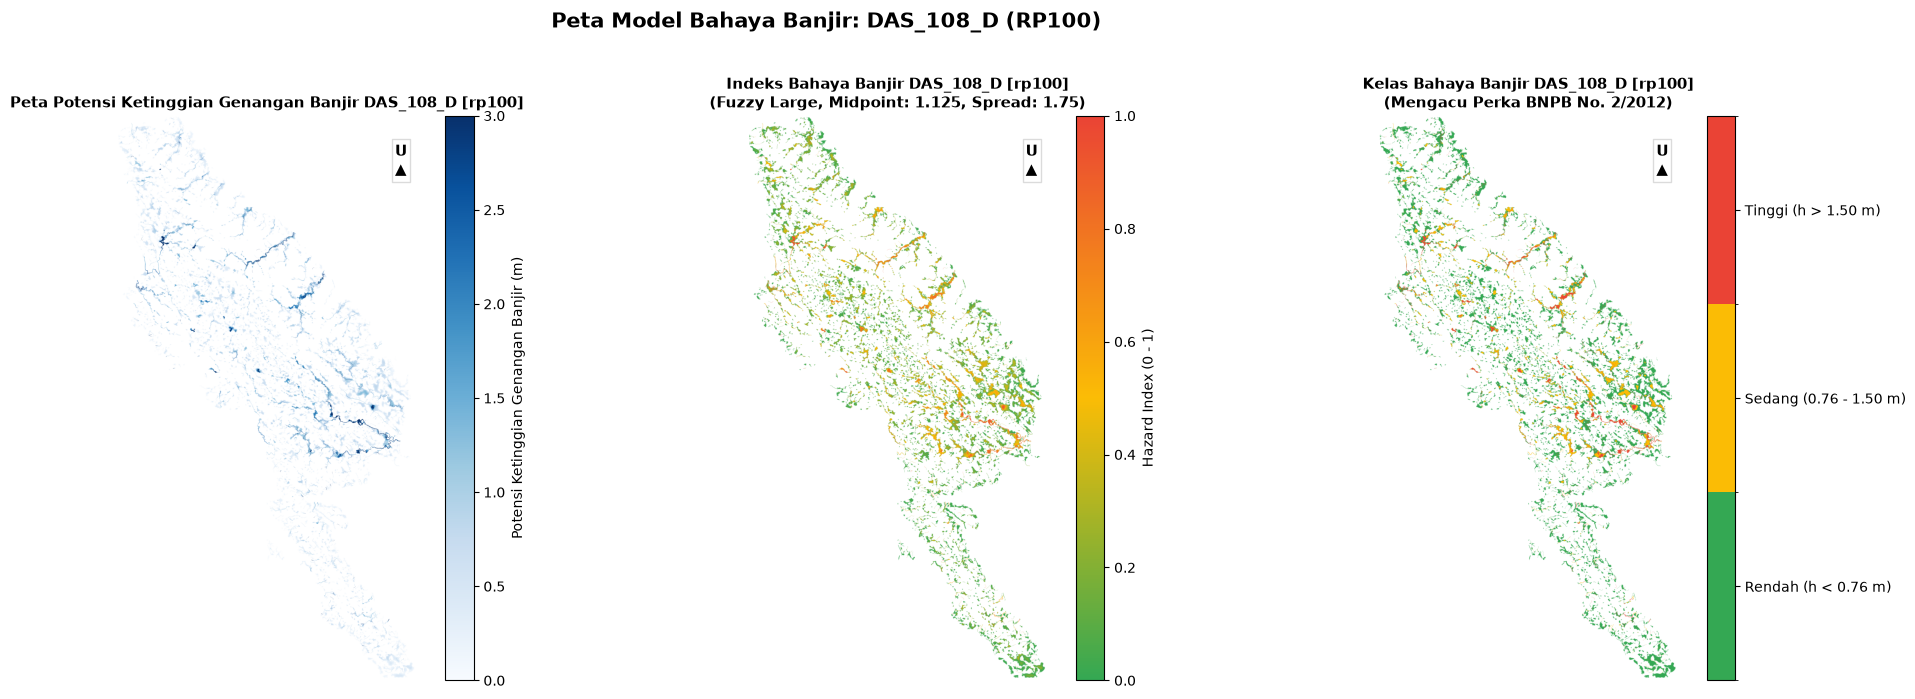

In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap, BoundaryNorm
import rasterio
import numpy as np
from pathlib import Path

# Select which completed run to inspect (defaults to first in list)
PLOT_DAS = SELECTED_CLUSTERS[0]
PLOT_RP = SELECTED_RPS[0]

das_tag = "DAS" + PLOT_DAS[4:] if PLOT_DAS.upper().startswith("DAS_") else (PLOT_DAS.upper() if PLOT_DAS.upper().startswith("DAS") else f"DAS{PLOT_DAS}")
rp_tag = f"RP{PLOT_RP[2:]}" if PLOT_RP.lower().startswith("rp") else f"RP{PLOT_RP}"
prefix = f"{das_tag}_{rp_tag}"
plot_dir = Path(OUTPUT_MAPS_DIR) / PLOT_DAS / PLOT_RP
depth_path = plot_dir / f"{prefix}_Flood_Depth.tif"
if not depth_path.exists():
    depth_path = plot_dir / "flood_depth_10m.tif"
fhi_path = plot_dir / f"{prefix}_FloodHazard_Index.tif"
if not fhi_path.exists():
    fhi_path = plot_dir / "flood_hazard_index.tif"
hazard_path = plot_dir / f"{prefix}_FloodHazard_Classes.tif"
if not hazard_path.exists():
    hazard_path = plot_dir / "hazard_class_perka2012.tif"

if depth_path.exists():
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 7))
    
    # 1. Flood Inundation Depth Map (10m FABDEM Downscaled)
    with rasterio.open(depth_path) as src_d:
        depth_data = src_d.read(1)
        depth_masked = np.where(depth_data < 0.05, np.nan, depth_data)
        # SFINCS raster arrays have dy > 0 (row 0 is south); origin='lower' ensures North is at the top
        origin_mode = "lower" if src_d.transform.e > 0 else "upper"
        im1 = ax1.imshow(depth_masked, cmap="Blues", vmin=0, vmax=3.0, origin=origin_mode)
        plt.colorbar(im1, ax=ax1, label="Potensi Ketinggian Genangan Banjir (m)", fraction=0.046, pad=0.04)
        ax1.set_title(f"Peta Potensi Ketinggian Genangan Banjir {PLOT_DAS} [{PLOT_RP}]", fontsize=11, fontweight="bold")
        ax1.axis("off")
        
    # 2. Continuous Flood Hazard Index (Fuzzy Large: 0 to 1)
    # Cartographic continuous ramp: Rendah (#34A853) -> Sedang (#FBBC05) -> Tinggi (#EA4335)
    cmap_fhi = LinearSegmentedColormap.from_list("fhi_continuous", ["#34A853", "#FBBC05", "#EA4335"])
    if fhi_path.exists():
        with rasterio.open(fhi_path) as src_f:
            fhi_data = src_f.read(1)
            im2 = ax2.imshow(fhi_data, cmap=cmap_fhi, vmin=0.0, vmax=1.0, origin=origin_mode)
            plt.colorbar(im2, ax=ax2, label="Hazard Index (0 - 1)", fraction=0.046, pad=0.04)
            ax2.set_title(f"Indeks Bahaya Banjir {PLOT_DAS} [{PLOT_RP}]\n(Fuzzy Large, Midpoint: 1.125, Spread: 1.75)", fontsize=11, fontweight="bold")
            ax2.axis("off")
            
    # 3. Perka BNPB No. 2/2012 Hazard Classification Map (Low, Medium, High)
    if hazard_path.exists():
        with rasterio.open(hazard_path) as src_h:
            hazard_data = src_h.read(1)
            hazard_masked = np.where(hazard_data == 0, np.nan, hazard_data)
            cmap_bnpb = ListedColormap(["#34A853", "#FBBC05", "#EA4335"])  # Rendah (#34A853), Sedang (#FBBC05), Tinggi (#EA4335)
            norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5], cmap_bnpb.N)
            im3 = ax3.imshow(hazard_masked, cmap=cmap_bnpb, norm=norm, origin=origin_mode)
            cbar = plt.colorbar(im3, ax=ax3, ticks=[1, 2, 3], fraction=0.046, pad=0.04)
            cbar.ax.set_yticklabels(["Rendah (h < 0.76 m)", "Sedang (0.76 - 1.50 m)", "Tinggi (h > 1.50 m)"])
            ax3.set_title(f"Kelas Bahaya Banjir {PLOT_DAS} [{PLOT_RP}]\n(Mengacu Perka BNPB No. 2/2012)", fontsize=11, fontweight="bold")
            ax3.axis("off")

    # Add cartographic North arrow to each map panel
    for ax in (ax1, ax2, ax3):
        ax.annotate(
            "U\n▲",
            xy=(0.95, 0.92),
            xycoords="axes fraction",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            bbox=dict(boxstyle="square,pad=0.2", facecolor="white", alpha=0.7, edgecolor="#cccccc"),
        )
            
    plt.suptitle(f"Peta Model Bahaya Banjir: {PLOT_DAS} ({PLOT_RP.upper()})\n", fontsize=15, fontweight="bold", y=0.98)
    plt.tight_layout()
    plt.show()
else:
    print(f"Output not found yet: {depth_path}. Please execute Steps 1-4 first.")


---
## 7. Step 6 — 36-Hour Flood Wave Propagation Animation

Extracts dynamic hourly water level slices ($t=1\text{h}, 2\text{h}, \dots, 24\text{h}$) from `sfincs_map.nc`, overlays transient flood depths over the terrain elevation model, and compiles a high-resolution looping animated GIF (`DASXXX_RPYYY_Flood_Animation.gif`).



==================== [DAS_108_D][rp100] GENERATING FLOOD PROPAGATION ANIMATION ====================
[DAS_108_D][rp100] Rendering 37-frame animation to outputs\DAS_108_D\rp100\DAS108_D_RP100_Flood_Animation.gif...
[OK] Unambiguously matched cluster 'DAS_108_D' in column 'ID_Cluster' -> 'DAS_108_D'
[DAS_108_D][rp100] Animation compiled: outputs\DAS_108_D\rp100\DAS108_D_RP100_Flood_Animation.gif


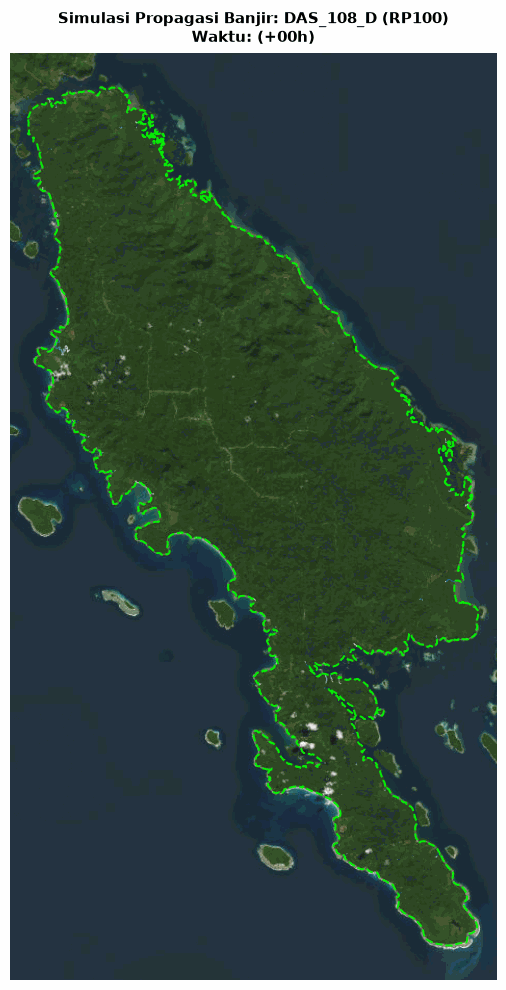

In [9]:
from IPython.display import Image, display

for das_id in SELECTED_CLUSTERS:
    for rp in SELECTED_RPS:
        print(f"\n==================== [{das_id}][{rp}] GENERATING FLOOD PROPAGATION ANIMATION ====================")
        anim_path = create_sfincs_flood_animation(
            das_id=das_id,
            rp=rp,
            base_model_dir=OUTPUT_MODELS_DIR,
            output_maps_dir=OUTPUT_MAPS_DIR,
            das_clusters_gpkg=DAS_CLUSTERS_GPKG,
            kecamatan_gpkg="data/boundary_kecamatan.gpkg",
            kabkot_gpkg="data/boundary_kabkot.gpkg",
            lake_gpkg="data/lake.gpkg",
            fps=2,
            hmin=0.05,
            vmax=3.0,
        )
        display(Image(filename=anim_path))
